In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import cv2
from PIL import Image, ImageFile
import os
import math
from pathlib import Path


import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import (
    Dataset,
    DataLoader,
    Subset,
    TensorDataset,
    random_split
)
import torchvision.transforms as transforms
from torchsummary import summary
from transformers import AutoImageProcessor, AutoModel
from collections import defaultdict
from sklearn.metrics import roc_curve, auc
from tqdm.auto import tqdm
import warnings
import random


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


ImageFile.LOAD_TRUNCATED_IMAGES = True

In [2]:
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
torch.cuda.manual_seed_all(42)

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mahdieizadpanah/sapienza-university-mobile-palmprint-databasesmpd")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/mahdieizadpanah/sapienza-university-mobile-palmprint-databasesmpd


In [4]:
def preprocess_palmprint(
    image_path,
    output_size=224
):

    pil_img = Image.open(
        image_path
    ).convert("RGB")

    img = np.array(pil_img)

    gray = cv2.cvtColor(
        img,
        cv2.COLOR_RGB2GRAY
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8,8)
    )

    gray = clahe.apply(gray)

    gray = cv2.GaussianBlur(
        gray,
        (3,3),
        0
    )

    h, w = gray.shape

    crop_ratio = 0.7

    new_h = int(h * crop_ratio)
    new_w = int(w * crop_ratio)

    start_y = (h - new_h) // 2
    start_x = (w - new_w) // 2

    gray = gray[
        start_y:start_y + new_h,
        start_x:start_x + new_w
    ]

    gray = cv2.resize(
        gray,
        (output_size, output_size)
    )

    return gray

In [5]:
class palmprintDataset(Dataset):

    def __init__(
        self,
        root_dir,
        class_ids=None,
        transform=None
    ):

        self.root_dir = Path(root_dir)
        self.transform = transform
        self.samples = []

        self.clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )

        all_folders = [
            f for f in self.root_dir.iterdir()
            if f.is_dir()
        ]

        all_folders.sort(
            key=lambda x: x.name
        )

        # If no class_ids are provided, use all classes
        if class_ids is None:
            class_ids = list(range(len(all_folders)))

        # Select only the requested folders
        selected_folders = [
            all_folders[i]
            for i in class_ids
        ]

        # Labels are remapped to 0...len(class_ids)-1
        for label, folder_path in enumerate(selected_folders):

            image_paths = sorted(
                folder_path.glob("*.JPG")
            )

            for img_path in image_paths:

                roi = preprocess_palmprint(str(img_path))
                roi = np.stack([roi, roi, roi], axis=-1)
                
                self.samples.append(
                    (roi, label)
                )

        print(
            f"Loaded {len(selected_folders)} classes with "
            f"{len(self.samples)} images."
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        image, label = self.samples[idx]

        image = Image.fromarray(image)

        if self.transform:
            image = self.transform(image)

        return image, label

In [6]:
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.2370, 0.2370, 0.2370], 
        std=[0.1592, 0.1592, 0.1592]
    )
])

dataset_path = "/kaggle/input/datasets/mahdieizadpanah/sapienza-university-mobile-palmprint-databasesmpd/Sapienza University Mobile Palmprint Database(SMPD)"

master_dataset = palmprintDataset(
    root_dir=dataset_path,
    class_ids=list(range(70)),
    transform=data_transforms
)

train_indices = []
val_indices = []
test_indices = []

for idx in range(len(master_dataset)):

    img_pos = (idx % 40) + 1   

    # Test images
    if img_pos in [1,2,11,12,21,22,31,32]:
        test_indices.append(idx)

    # Validation images
    elif img_pos in [3,4,13,14,23,24,33,34]:
        val_indices.append(idx)

    # Remaining images -> Train
    else:
        train_indices.append(idx)

train_dataset = Subset(master_dataset, train_indices)
val_dataset   = Subset(master_dataset, val_indices)
test_dataset  = Subset(master_dataset, test_indices)

unknown_dataset = palmprintDataset(
    root_dir=dataset_path,
    class_ids=list(range(70, 92)),
    transform=data_transforms
)
        
print(f"Train dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")
print(f"Test dataset size: {len(unknown_dataset)}")

Loaded 70 classes with 2797 images.
Loaded 22 classes with 880 images.
Train dataset size: 1677
Validation dataset size: 560
Test dataset size: 560
Test dataset size: 880


In [7]:
batch_size = 32

train_loader = DataLoader(
    train_dataset, 
    batch_size=batch_size, 
    shuffle=True,      
    num_workers=4,     
    pin_memory=True    
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=batch_size, 
    shuffle=False,     
    num_workers=4,     
    pin_memory=True    
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=4
)

unknown_test_loader = DataLoader(
    unknown_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=4
)

images, labels = next(iter(train_loader))
print(f"Batch ecg images shape: {images.shape}") 
print(f"Batch labels shape: {labels.shape}") 
print(f"Min label: {labels.min().item()}, Max label: {labels.max().item()}") 

Batch ecg images shape: torch.Size([32, 3, 224, 224])
Batch labels shape: torch.Size([32])
Min label: 3, Max label: 65


In [28]:
class palmCNN(nn.Module):
    def __init__(self, in_channels=3, emb_dim=512):
        super(palmCNN, self).__init__()
        
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=7, stride=1, padding=3),
            nn.Conv2d(64, 64, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2), # Output: 112 x 112 x 64
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(64)
        )
        
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=7, stride=1, padding=3),
            nn.Conv2d(128, 128, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2), # Output: 56 x 56 x 128
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(128)
        )
                
        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=5, stride=1, padding=2),
            nn.Conv2d(256, 256, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(256)
        )
 
        self.block4 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=5, stride=1, padding=2),
            nn.Conv2d(512, 512, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2), 
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(512)
        )
 
        self.block5 = nn.Sequential(
            nn.Conv2d(512, 512, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2), 
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(512)
        )
 
        self.fc = nn.Sequential(
        nn.Flatten(),
        nn.Linear(7 * 7 * 512, 1024),
        nn.BatchNorm1d(1024),
        nn.ReLU(),
        nn.Dropout(0.4),
        nn.Linear(1024, emb_dim)
        )

    def forward(self, x):
     
        x = self.block1(x)
        
        x = self.block2(x)
        
        x = self.block3(x)

        x = self.block4(x)

        x = self.block5(x)
        x = self.fc(x)
        return x

In [9]:
class ArcFaceLoss(nn.Module):
    def __init__(self, in_features, num_classes, s=64.0, m=0.5, easy_margin=False):
        super().__init__()

        self.in_features = in_features
        self.num_classes = num_classes

        self.s = s
        self.m = m
        self.easy_margin = easy_margin

        self.weight = nn.Parameter(torch.empty(num_classes, in_features))
        nn.init.xavier_uniform_(self.weight)

        self.cos_m = math.cos(m)
        self.sin_m = math.sin(m)
        self.th = math.cos(math.pi - m)
        self.mm = math.sin(math.pi - m) * m


    def forward(self, embeddings, labels):
       
        embeddings = F.normalize(embeddings, dim=1)
        weight = F.normalize(self.weight, dim=1)

        cosine = F.linear(embeddings, weight)  

        cosine = cosine.clamp(-1.0 + 1e-7, 1.0 - 1e-7)

        sine = torch.sqrt(1.0 - cosine.pow(2))
        phi = cosine * self.cos_m - sine * self.sin_m

        if self.easy_margin:
            phi = torch.where(cosine > 0, phi, cosine)
        else:
            phi = torch.where(cosine > self.th, phi, cosine - self.mm)

        one_hot = torch.zeros_like(cosine)
        one_hot.scatter_(1, labels.view(-1, 1), 1.0)

        logits = (one_hot * phi) + ((1.0 - one_hot) * cosine)
        logits *= self.s

        loss = F.cross_entropy(logits, labels)

        return loss, cosine

In [29]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

lr = 1e-4
weight_decay = 1e-4
num_classes = 70

model = palmCNN(emb_dim=512).to(device)
print(model)
print(summary(model,(3,224,224)))

images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)

outputs = model(images)
print(f"Output shape: {outputs.shape}")

criterion = ArcFaceLoss(
    in_features=512,
    num_classes=num_classes,
    s=64,
    m=0.5
).to(device)

optimizer = torch.optim.AdamW(
    list(model.parameters()) + list(criterion.parameters()),
    lr=1e-4, weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=3
)


cuda
palmCNN(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): ReLU()
    (4): Dropout2d(p=0.3, inplace=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (block2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): Conv2d(128, 128, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): ReLU()
    (4): Dropout2d(p=0.3, inplace=False)
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (block3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Conv2d(256, 256, kernel_size=(5, 5), stride=(1, 1), paddi

In [11]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.stop = False

    def __call__(self, val_loss):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True

In [12]:
scaler = torch.amp.GradScaler("cuda")

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            embeddings = model(images)
            loss, _ = criterion(embeddings, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

    return running_loss / len(loader)

In [13]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    correct = 0
    total = 0
    running_loss = 0.0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        embeddings = model(images)

        loss, cosine = criterion(embeddings, labels)
        running_loss += loss.item()

        weight = F.normalize(criterion.weight, dim=1)
        logits = embeddings @ weight.T

        preds = logits.argmax(dim=1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / len(loader), 100.0 * correct / total

In [30]:
warnings.filterwarnings("ignore")

train_losses = []
val_losses = []
val_accs = []

num_epochs = 30
early_stopping = EarlyStopping(patience=5, min_delta=1e-4)
best_val_loss = float("inf")

for epoch in range(num_epochs):

    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.2f}% "
    ) 

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_model.pth")
        print("--> Best model saved.")

    early_stopping(val_loss)
    if early_stopping.stop:
        print("--> Early stopping triggered.")
        break

Epoch [1/30] Train Loss: 37.0888 | Val Loss: 34.5132 | Val Accuracy: 13.75% 
--> Best model saved.
Epoch [2/30] Train Loss: 34.9377 | Val Loss: 33.0420 | Val Accuracy: 33.93% 
--> Best model saved.
Epoch [3/30] Train Loss: 33.9931 | Val Loss: 32.2835 | Val Accuracy: 42.32% 
--> Best model saved.
Epoch [4/30] Train Loss: 33.1133 | Val Loss: 31.6076 | Val Accuracy: 50.36% 
--> Best model saved.
Epoch [5/30] Train Loss: 32.1818 | Val Loss: 29.9570 | Val Accuracy: 66.25% 
--> Best model saved.
Epoch [6/30] Train Loss: 31.0101 | Val Loss: 28.2697 | Val Accuracy: 73.93% 
--> Best model saved.
Epoch [7/30] Train Loss: 29.2881 | Val Loss: 27.6226 | Val Accuracy: 72.32% 
--> Best model saved.
Epoch [8/30] Train Loss: 27.0739 | Val Loss: 22.7204 | Val Accuracy: 80.71% 
--> Best model saved.
Epoch [9/30] Train Loss: 24.2006 | Val Loss: 16.7949 | Val Accuracy: 88.75% 
--> Best model saved.
Epoch [10/30] Train Loss: 20.9570 | Val Loss: 13.6032 | Val Accuracy: 89.64% 
--> Best model saved.
Epoch [11

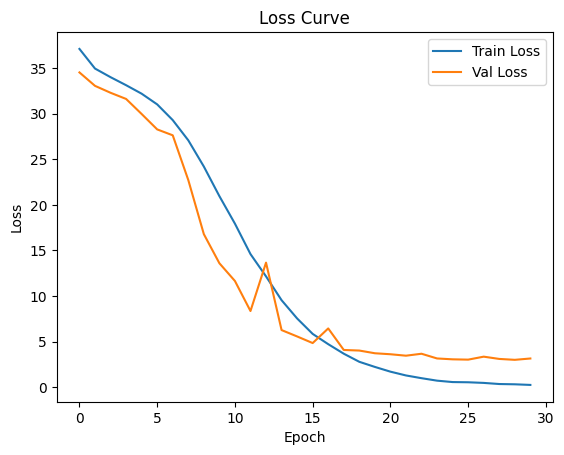

In [31]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss Curve")
plt.show()

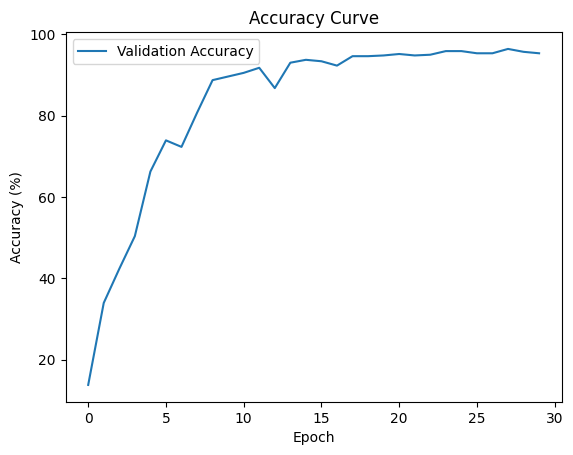

In [34]:
plt.figure()
plt.plot(val_accs, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.title("Accuracy Curve")
plt.show()

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

@torch.no_grad()
def compute_identification_metrics(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    weight = F.normalize(
        criterion.weight,
        dim=1
    )

    all_preds = []
    all_labels = []

    rank1 = 0
    rank5 = 0
    rank10 = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        embs = F.normalize(
            model(images),
            dim=1
        )

        logits = embs @ weight.T

        preds = logits.argmax(1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        top5 = logits.topk(
            k=min(5, logits.size(1)),
            dim=1
        ).indices

        top10 = logits.topk(
            k=min(10, logits.size(1)),
            dim=1
        ).indices

        rank1 += (preds == labels).sum().item()

        rank5 += (
            top5 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        rank10 += (
            top10 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        total += labels.size(0)

    return {
        "rank1": 100 * rank1 / total,
        "rank5": 100 * rank5 / total,
        "rank10": 100 * rank10 / total,
        "precision": precision_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100,
        "recall": recall_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100,
        "f1": f1_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100
    }

In [32]:
id_metrics = compute_identification_metrics(
    model,
    test_loader,
    criterion,
    device
)

print("\n===== Identification =====")
print(f"Rank-1 Accuracy : {id_metrics['rank1']:.2f}%")
print(f"Rank-5 Accuracy : {id_metrics['rank5']:.2f}%")
print(f"Rank-10 Accuracy: {id_metrics['rank10']:.2f}%")
print(f"Precision       : {id_metrics['precision']:.2f}%")
print(f"Recall          : {id_metrics['recall']:.2f}%")
print(f"F1 Score        : {id_metrics['f1']:.2f}%")


===== Identification =====
Rank-1 Accuracy : 94.46%
Rank-5 Accuracy : 96.61%
Rank-10 Accuracy: 97.50%
Precision       : 95.13%
Recall          : 94.46%
F1 Score        : 94.40%


In [35]:
torch.save(model.state_dict(), "Palm-Model-Weight")

In [36]:
model_1 = palmCNN(emb_dim=512)

model_1.load_state_dict(
    torch.load("/kaggle/working/Palm-Model-Weight")
)

model_1.to(device)

palmCNN(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): ReLU()
    (4): Dropout2d(p=0.3, inplace=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (block2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): Conv2d(128, 128, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): ReLU()
    (4): Dropout2d(p=0.3, inplace=False)
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (block3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Conv2d(256, 256, kernel_size=(5, 5), stride=(1, 1), padding=(2

In [37]:
model_2 = torch.hub.load('facebookresearch/dinov2', 'dinov2_vitl14')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_2 = model_2.to(device)
model_2.eval()

print(model_2)
print(summary(model_2, (3, 224, 224)))

dummy_image = torch.randn(1, 3, 224, 224).to(device) 
with torch.no_grad():

    features = model_2(dummy_image)

print("Extracted feature shape:", features.shape)

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


DinoVisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 1024, kernel_size=(14, 14), stride=(14, 14))
    (norm): Identity()
  )
  (blocks): ModuleList(
    (0-23): 24 x NestedTensorBlock(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (attn): MemEffAttention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
      (ls2): LayerScale()
      (drop_path2): Identity()
    )
  )
  (norm): LayerNorm((1024,), eps=1e-06, element

In [40]:
@torch.no_grad()
def extract_fused_features(loader, model_1, model_2, device):

    model_1.eval()
    model_2.eval()

    features = []
    labels = []

    for images, target in loader:

        images = images.to(device, non_blocking=True)

        f1 = model_1(images)
        f2 = model_2(images)

        f1 = F.normalize(f1, dim=1)
        f2 = F.normalize(f2, dim=1)

        fused = torch.cat([f1, f2], dim=1)

        features.append(fused.cpu())
        labels.append(target)

    features = torch.cat(features, dim=0)
    labels = torch.cat(labels, dim=0)

    return features.numpy(), labels.numpy()

In [41]:
warnings.filterwarnings("ignore")

X_train, y_train = extract_fused_features(
    train_loader,
    model_1,
    model_2,
    device
)

X_val, y_val = extract_fused_features(
    val_loader,
    model_1,
    model_2,
    device
)

X_test, y_test = extract_fused_features(
    test_loader,
    model_1,
    model_2,
    device
)

X_test_unknown, y_test_unknown = extract_fused_features(
   unknown_test_loader,
    model_1,
    model_2,
    device
)

print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)
print("Test(unknown) :", X_test_unknown.shape, y_test_unknown.shape)

Train: (1677, 1536) (1677,)
Val  : (560, 1536) (560,)
Test : (560, 1536) (560,)
Test(unknown) : (880, 1536) (880,)


In [42]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import normalize
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X_train_ml = normalize(X_train)
X_val_ml = normalize(X_val)
X_test_ml = normalize(X_test)

pipeline = make_pipeline(

    SelectKBest(
        score_func=mutual_info_classif,
        k=512
    ),

    StandardScaler(),

    SVC(
        kernel='rbf',
        probability=True
    )
)

pipeline.fit(X_train_ml, y_train)

val_pred = pipeline.predict(X_val_ml)

val_acc = accuracy_score(
    y_val,
    val_pred
)

print("Validation Accuracy:", val_acc)

y_pred = pipeline.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Validation Accuracy: 0.9589285714285715
Accuracy  : 0.9482
Precision : 0.9540
Recall    : 0.9482
F1-Score  : 0.9465


In [43]:
from sklearn.svm import LinearSVC

model = make_pipeline(
    SelectKBest(
        score_func=mutual_info_classif,
        k=512
    ),
    StandardScaler(),
    LinearSVC(
        C=1.0,
        class_weight='balanced',
        max_iter=10000
    )
)

model.fit(X_train_ml, y_train)

val_pred = model.predict(X_val_ml)
val_acc = accuracy_score(y_val, val_pred)

print("Validation Accuracy:", val_acc)

y_pred = model.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Validation Accuracy: 0.9660714285714286
Accuracy  : 0.9482
Precision : 0.9577
Recall    : 0.9482
F1-Score  : 0.9478


In [44]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(
    n_neighbors=5,
    metric='cosine'
)

knn.fit(X_train_ml, y_train)

y_pred = knn.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Accuracy  : 0.9464
Precision : 0.9531
Recall    : 0.9464
F1-Score  : 0.9452


In [45]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(
    max_iter=5000,
    class_weight='balanced'
)

lr.fit(X_train_ml, y_train)

y_pred = lr.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Accuracy  : 0.9482
Precision : 0.9551
Recall    : 0.9482
F1-Score  : 0.9476


In [46]:
X_train_tensor = torch.from_numpy(X_train).float()
y_train_tensor = torch.from_numpy(y_train).long()

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

X_val_tensor = torch.from_numpy(X_val).float()
y_val_tensor = torch.from_numpy(y_val).long()

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

X_test_tensor = torch.from_numpy(X_test).float()
y_test_tensor = torch.from_numpy(y_test).long()

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

X_test_unknown_tensor = torch.from_numpy(X_test_unknown).float()
y_test_unknown_tensor = torch.from_numpy(y_test_unknown).long()

unknown_test_dataset = TensorDataset(
    X_test_unknown_tensor,
    y_test_unknown_tensor
)

In [47]:
# ------------------- Train -------------------
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# ------------------- Validation -------------------
val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# ------------------- Test -------------------
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# ------------------- Unknown Test -------------------
unknown_test_loader = DataLoader(
    unknown_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [48]:
class FusionClassifier(nn.Module):

    def __init__(self,
                 input_dim=2048,
                 num_classes=200):

        super().__init__()

        self.features = nn.Sequential(
            nn.Linear(input_dim, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),

            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True)
        )
        self.classifier = nn.Linear(
            512,
            num_classes
        )

    def forward(self, x):

        feat = self.features(x)

        logits = self.classifier(feat)

        return logits, feat

In [49]:
lr = 1e-4
weight_decay = 1e-4

model = FusionClassifier(input_dim=1536, num_classes=70).to(device)

print(model)
print(summary(model, (1536,)))


images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)

logits, feat = model(images)

print("Logits shape:", logits.shape)
print("Feature shape:", feat.shape)

criterion = nn.CrossEntropyLoss().to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=3
)

FusionClassifier(
  (features): Sequential(
    (0): Linear(in_features=1536, out_features=1024, bias=True)
    (1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=1024, out_features=512, bias=True)
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
  )
  (classifier): Linear(in_features=512, out_features=70, bias=True)
)
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                 [-1, 1024]       1,573,888
       BatchNorm1d-2                 [-1, 1024]           2,048
              ReLU-3                 [-1, 1024]               0
           Dropout-4                 [-1, 1024]               0
            Linear-5                  [-1, 512]         524,800
       BatchNorm1d-6          

In [50]:
scaler = torch.amp.GradScaler("cuda")
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0

    for features, labels in loader:
        features = features.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits, feat = model(features)

            loss = criterion(
                logits,
                labels
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

    return running_loss / len(loader)

In [51]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for features, labels in loader:
        features = features.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits, _ = model(features)
        loss = criterion(logits, labels)

        running_loss += loss.item()

        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    avg_loss = running_loss / len(loader)
    accuracy = 100.0 * correct / total

    return avg_loss, accuracy

In [52]:
warnings.filterwarnings("ignore")

train_losses = []
val_losses = []
val_accs = []

num_epochs = 100
early_stopping = EarlyStopping(patience=25, min_delta=1e-4)
best_val_acc = 0.0

for epoch in range(num_epochs):

    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.2f}% "
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_model.pth")
        print("--> Best model saved.")

    early_stopping(val_acc)
    if early_stopping.stop:
        print("--> Early stopping triggered.")
        break

Epoch [1/100] Train Loss: 2.7289 | Val Loss: 3.4043 | Val Accuracy: 93.04% 
--> Best model saved.
Epoch [2/100] Train Loss: 0.8887 | Val Loss: 0.7430 | Val Accuracy: 95.71% 
--> Best model saved.
Epoch [3/100] Train Loss: 0.4137 | Val Loss: 0.4990 | Val Accuracy: 95.71% 
Epoch [4/100] Train Loss: 0.2417 | Val Loss: 0.4094 | Val Accuracy: 95.71% 
Epoch [5/100] Train Loss: 0.1644 | Val Loss: 0.3503 | Val Accuracy: 95.89% 
--> Best model saved.
Epoch [6/100] Train Loss: 0.1295 | Val Loss: 0.3341 | Val Accuracy: 96.07% 
--> Best model saved.
Epoch [7/100] Train Loss: 0.1125 | Val Loss: 0.3120 | Val Accuracy: 96.07% 
Epoch [8/100] Train Loss: 0.0996 | Val Loss: 0.3029 | Val Accuracy: 95.89% 
Epoch [9/100] Train Loss: 0.0883 | Val Loss: 0.2889 | Val Accuracy: 95.89% 
Epoch [10/100] Train Loss: 0.0797 | Val Loss: 0.2814 | Val Accuracy: 95.89% 
Epoch [11/100] Train Loss: 0.0744 | Val Loss: 0.2753 | Val Accuracy: 95.89% 
Epoch [12/100] Train Loss: 0.0715 | Val Loss: 0.2731 | Val Accuracy: 95.89

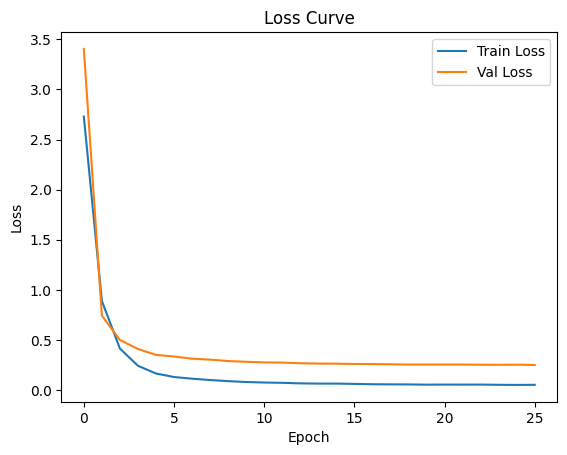

In [53]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss Curve")
plt.show()

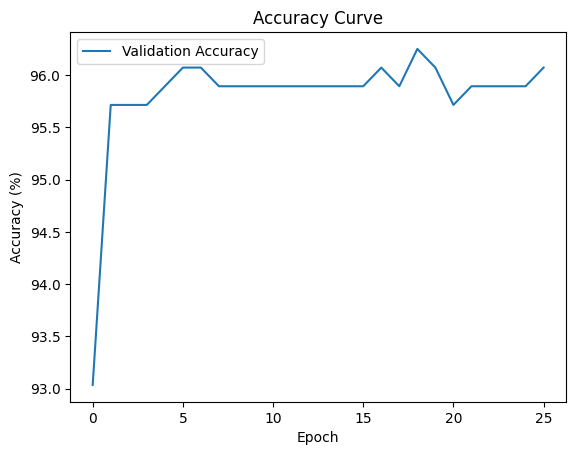

In [54]:
plt.figure()
plt.plot(val_accs, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.title("Accuracy Curve")
plt.show()

In [55]:
model.load_state_dict(
    torch.load("best_model.pth")
)

<All keys matched successfully>

In [56]:
@torch.no_grad()
def compute_identification_metrics(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    all_preds = []
    all_labels = []

    rank1 = 0
    rank5 = 0
    rank10 = 0
    total = 0

    for features, labels in loader:

        features = features.to(device)
        labels = labels.to(device)

        logits, _ = model(features)

        preds = logits.argmax(1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        top5 = logits.topk(
            k=min(5, logits.size(1)),
            dim=1
        ).indices

        top10 = logits.topk(
            k=min(10, logits.size(1)),
            dim=1
        ).indices

        rank1 += (preds == labels).sum().item()

        rank5 += (
            top5 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        rank10 += (
            top10 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        total += labels.size(0)

    return {
        "rank1": 100 * rank1 / total,
        "rank5": 100 * rank5 / total,
        "rank10": 100 * rank10 / total,
        "precision": precision_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100,
        "recall": recall_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100,
        "f1": f1_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100
    }

In [57]:
@torch.no_grad()
def compute_cmc(
    model,
    loader,
    device,
    max_rank=20
):

    model.eval()

    cmc = np.zeros(max_rank)
    total = 0

    for features, labels in loader:

        features = features.to(device)
        labels = labels.to(device)

        logits, _ = model(features)

        ranks = logits.argsort(
            dim=1,
            descending=True
        )

        for i in range(labels.size(0)):

            pos = (
                ranks[i] == labels[i]
            ).nonzero(
                as_tuple=True
            )[0].item()

            if pos < max_rank:
                cmc[pos:] += 1

        total += labels.size(0)

    return cmc / total

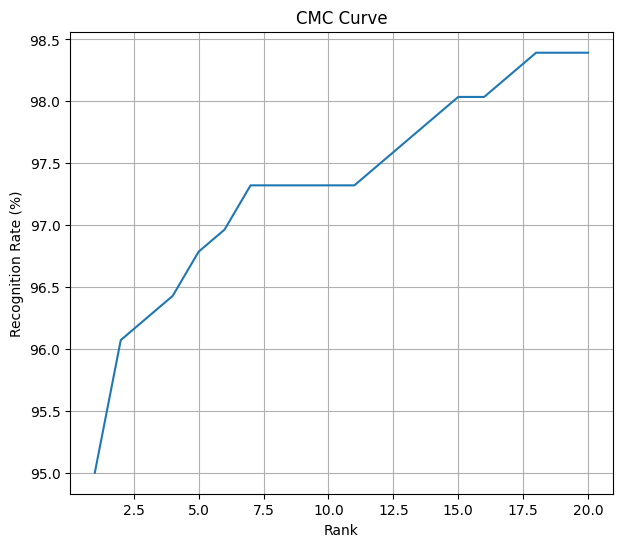

In [59]:
cmc = compute_cmc(
    model,
    test_loader,
    device
)

plt.figure(figsize=(7,6))

plt.plot(
    np.arange(1, len(cmc)+1),
    cmc * 100
)

plt.xlabel("Rank")
plt.ylabel("Recognition Rate (%)")
plt.title("CMC Curve")

plt.grid(True)
plt.show()

In [58]:
id_metrics = compute_identification_metrics(
    model,
    test_loader,
    criterion,
    device
)

print("\n===== Identification =====")
print(f"Rank-1 Accuracy : {id_metrics['rank1']:.2f}%")
print(f"Rank-5 Accuracy : {id_metrics['rank5']:.2f}%")
print(f"Rank-10 Accuracy: {id_metrics['rank10']:.2f}%")
print(f"Precision       : {id_metrics['precision']:.2f}%")
print(f"Recall          : {id_metrics['recall']:.2f}%")
print(f"F1 Score        : {id_metrics['f1']:.2f}%")


===== Identification =====
Rank-1 Accuracy : 95.00%
Rank-5 Accuracy : 96.79%
Rank-10 Accuracy: 97.32%
Precision       : 95.55%
Recall          : 95.00%
F1 Score        : 94.90%
